<a href="https://colab.research.google.com/github/Chow376/Project-399/blob/main/309.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks
from pathlib import Path
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import os
import json
import h5py

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import json
import pandas as pd

dfemg = pd.read_json('/content/drive/MyDrive/DATA /NICK/emg.json')
dfsub = pd.read_json('/content/drive/MyDrive/DATA /NICK/emg B.json')
dfevents = pd.read_json('/content/drive/MyDrive/DATA /NICK/events.jsonl', lines=True)

# Read session.json using a Series or standard dict
with open('/content/drive/MyDrive/DATA /NICK/session.json', 'r') as f:
    session_data = json.load(f)
dfsession = pd.Series(session_data)

def read_jrnl_with_nan(file_path):
    records = []
    with open(file_path, 'r', encoding='latin-1') as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    # Parse using native json loads and append valid records
                    records.append(json.loads(line))
                except json.JSONDecodeError:
                    # Skip lines that are not valid JSON (e.g. metadata header lines)
                    continue
    return pd.DataFrame(records)

# Read .jrnl files parsing with native json module and ignoring non-JSON rows
dftringo = read_jrnl_with_nan('/content/drive/MyDrive/DATA /NICK/tringo.jrnl')
dftreadmill = read_jrnl_with_nan('/content/drive/MyDrive/DATA /NICK/treadmill.jrnl')
dfpolar = read_jrnl_with_nan('/content/drive/MyDrive/DATA /NICK/polar.jrnl')

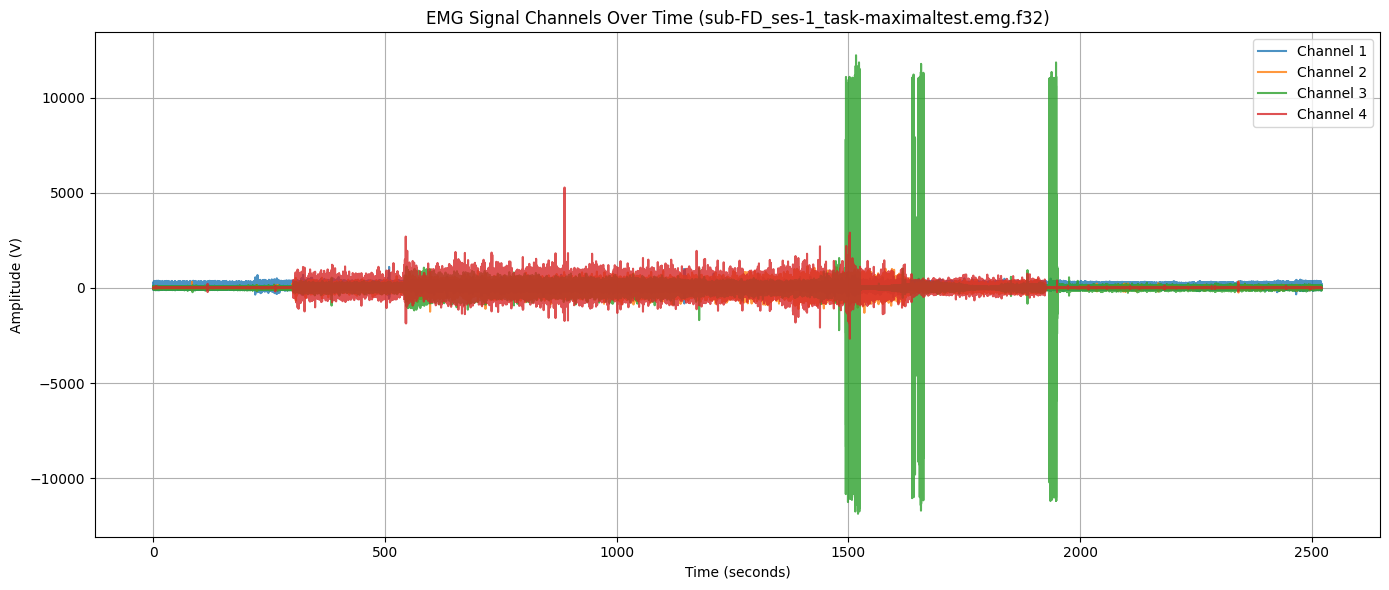

Successfully found and plotted: /content/drive/MyDrive/DATA /NICK/sub-FD_ses-1_task-maximaltest.emg.f32


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Restore built-in print if it was overridden
try:
    if 'print' in globals() and isinstance(globals()['print'], pd.DataFrame):
        del globals()['print']
except Exception:
    pass

# Let's extract file metadata from dfemg (or dfemgB if dfemg doesn't yield it)
emg_meta = dfemg.iloc[0]
binary_filename = emg_meta['file']
sample_rate = int(emg_meta.get('sample_rate', 2000))

# Recursively search for any .f32 file in Google Drive to find the data file
binary_path = None
search_root = '/content/drive/MyDrive/'

# First try to find the exact filename
for root, dirs, files in os.walk(search_root):
    if binary_filename in files:
        binary_path = os.path.join(root, binary_filename)
        break

# If not found by exact name, look for any .f32 file in Drive
if not binary_path:
    for root, dirs, files in os.walk(search_root):
        for f in files:
            if f.endswith('.f32'):
                binary_path = os.path.join(root, f)
                binary_filename = f
                break
        if binary_path:
            break

if binary_path and os.path.exists(binary_path):
    # Read the little-endian float32 binary file
    raw_emg = np.fromfile(binary_path, dtype='<f4')

    # Reshape based on number of active channels
    num_channels = len(dfemg)

    if len(raw_emg) % num_channels == 0:
        # Reshape to (samples, channels) since it is interleaved
        emg_data = raw_emg.reshape(-1, num_channels)

        # Create a time axis in seconds
        duration = len(emg_data) / sample_rate
        time_axis = np.linspace(0, duration, len(emg_data))

        # Plot the first few channels to keep the plot readable
        plt.figure(figsize=(14, 6))
        channels_to_plot = min(num_channels, 4)
        for ch in range(channels_to_plot):
            plt.plot(time_axis, emg_data[:, ch], label=f"Channel {ch + 1}", alpha=0.8)

        plt.title(f'EMG Signal Channels Over Time ({binary_filename})')
        plt.xlabel('Time (seconds)')
        plt.ylabel('Amplitude (V)')
        plt.legend(loc='upper right')
        plt.grid(True)
        plt.tight_layout()
        plt.show()

        print(f"Successfully found and plotted: {binary_path}")
    else:
        # Try reshaping with other standard channel configurations (e.g. 4, 8, 16)
        resolved = False
        for possible_ch in [4, 8, 16, 2]:
            if len(raw_emg) % possible_ch == 0:
                emg_data = raw_emg.reshape(-1, possible_ch)
                duration = len(emg_data) / sample_rate
                time_axis = np.linspace(0, duration, len(emg_data))

                plt.figure(figsize=(14, 6))
                for ch in range(min(possible_ch, 4)):
                    plt.plot(time_axis, emg_data[:, ch], label=f"Channel {ch + 1}", alpha=0.8)
                plt.title(f'EMG Signal Channels Over Time ({binary_filename} - assumed {possible_ch} ch)')
                plt.xlabel('Time (seconds)')
                plt.ylabel('Amplitude (V)')
                plt.legend(loc='upper right')
                plt.grid(True)
                plt.tight_layout()
                plt.show()
                resolved = True
                print(f"Successfully plotted using auto-detected {possible_ch} channels.")
                break
        if not resolved:
            print(f"Binary data size ({len(raw_emg)}) could not be mapped to common channel dimensions.")
else:
    print(f"Could not locate any raw EMG (.f32) file in {search_root}. Please ensure the file is uploaded to your Google Drive.")

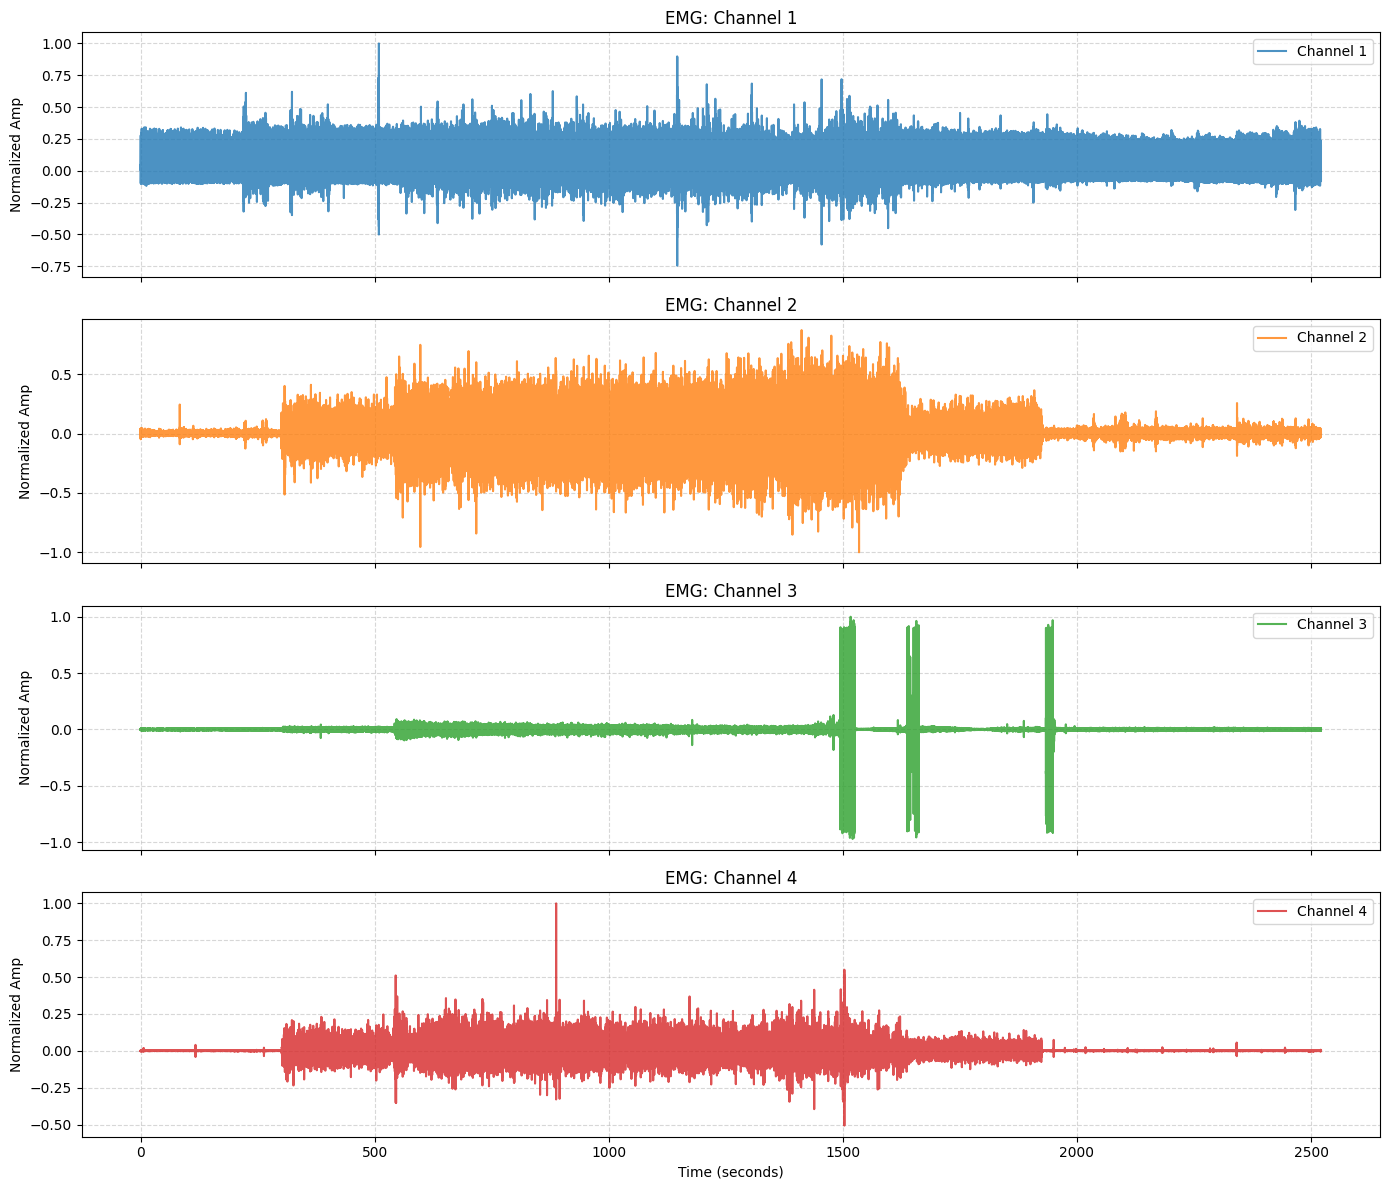

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Ensure we have the channel labels from dfemg metadata if available
try:
    # Map index/channel index to muscle/label names
    channel_names = dfemg['label'].tolist()
except Exception:
    channel_names = [f'Channel {i+1}' for i in range(num_channels)]

# Let's normalize the EMG signals (z-score normalization or min-max normalization)
# Here we will perform min-max normalization to scale amplitudes between -1 and 1
normalized_emg = np.zeros_like(emg_data)
for ch in range(num_channels):
    max_val = np.max(np.abs(emg_data[:, ch]))
    if max_val > 0:
        normalized_emg[:, ch] = emg_data[:, ch] / max_val
    else:
        normalized_emg[:, ch] = emg_data[:, ch]

# Plot each EMG channel on separate subplots
fig, axes = plt.subplots(num_channels, 1, figsize=(14, 3 * num_channels), sharex=True)
if num_channels == 1:
    axes = [axes]

for ch in range(num_channels):
    axes[ch].plot(time_axis, normalized_emg[:, ch], label=channel_names[ch], color=f'C{ch}', alpha=0.8)
    axes[ch].set_ylabel('Normalized Amp')
    axes[ch].set_title(f'EMG: {channel_names[ch]}')
    axes[ch].grid(True, linestyle='--', alpha=0.5)
    axes[ch].legend(loc='upper right')

axes[-1].set_xlabel('Time (seconds)')
plt.tight_layout()
plt.show()
#1= 7th rib heart 2= 3= 4=

To Do


*   Plot on seperate graphs
*   Label axis with correct EMG
normalise data







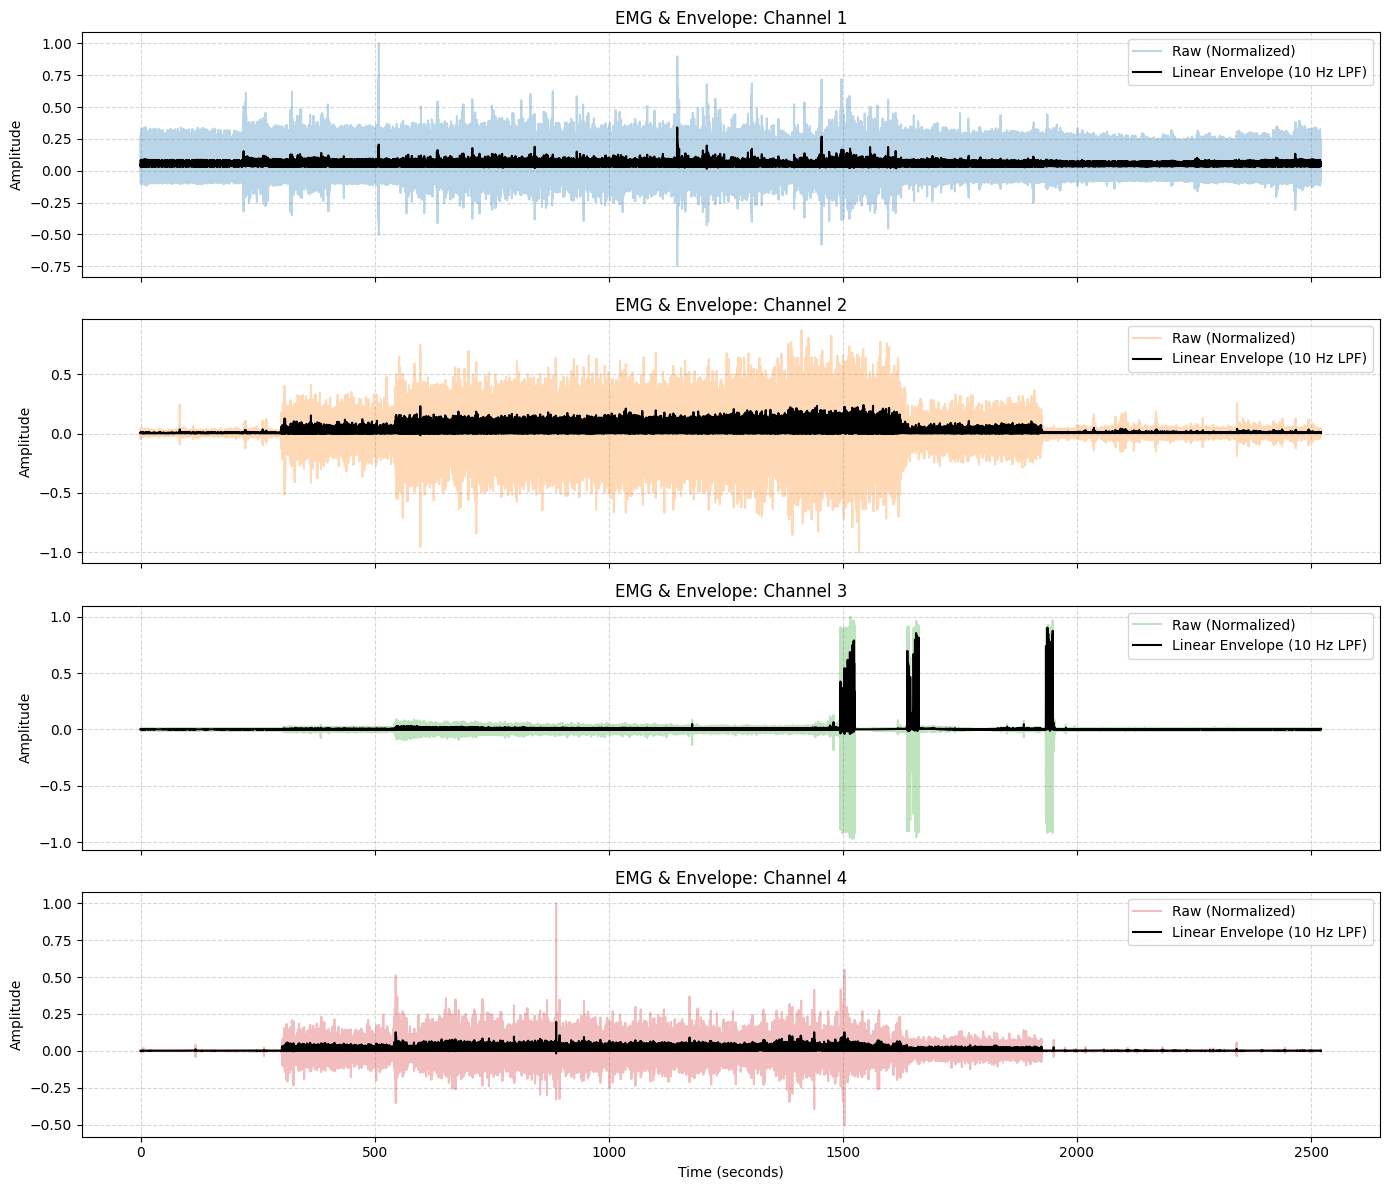

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# Define a low-pass filter function to create the linear envelope
def lowpass_filter(data, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y

# Parameters for envelope detection
cutoff_freq = 10.0  # Cutoff frequency in Hz for muscle contraction envelopes
fs = sample_rate    # Sampling frequency (2000 Hz)

# Ensure we have the channel labels
try:
    channel_names = dfemg['label'].tolist()
except Exception:
    channel_names = [f'Channel {i+1}' for i in range(num_channels)]

fig, axes = plt.subplots(num_channels, 1, figsize=(14, 3 * num_channels), sharex=True)
if num_channels == 1:
    axes = [axes]

for ch in range(num_channels):
    # 1. Full-wave rectification
    rectified_signal = np.abs(normalized_emg[:, ch])

    # 2. Low-pass filtering to obtain the linear envelope
    envelope = lowpass_filter(rectified_signal, cutoff_freq, fs, order=4)

    # Plot normalized raw EMG, rectified signal, and the linear envelope
    axes[ch].plot(time_axis, normalized_emg[:, ch], label='Raw (Normalized)', color=f'C{ch}', alpha=0.3)
    axes[ch].plot(time_axis, envelope, label='Linear Envelope (10 Hz LPF)', color='black', linewidth=1.5)

    axes[ch].set_ylabel('Amplitude')
    axes[ch].set_title(f'EMG & Envelope: {channel_names[ch]}')
    axes[ch].grid(True, linestyle='--', alpha=0.5)
    axes[ch].legend(loc='upper right')

axes[-1].set_xlabel('Time (seconds)')
plt.tight_layout()
plt.show()